In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_regression

In [2]:
np.random.seed(42)

In [3]:
X_nonlinear = np.linspace(-3, 3, 200)
y_nonlinear = np.sin(X_nonlinear) + np.random.normal(0, 0.1, X_nonlinear.shape)

In [4]:
X_outliers = np.random.uniform(-3, 3, 10)
y_outliers = np.random.uniform(-2, 2, 10)
X_total = np.concatenate([X_nonlinear, X_outliers])
y_total = np.concatenate([y_nonlinear, y_outliers])

In [5]:
high_dim_features = np.random.randn(len(X_total), 10)
df = pd.DataFrame(high_dim_features, columns=[f"feature_{i}" for i in range(10)])
df["X"] = X_total
df["target"] = y_total

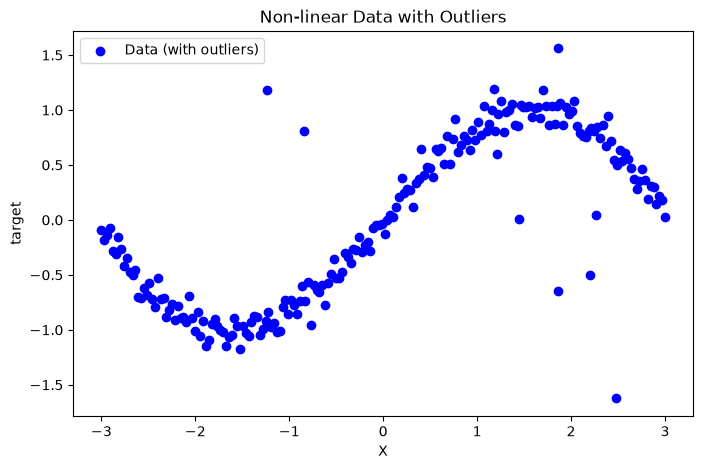

In [6]:
plt.figure(figsize=(8,5))
plt.scatter(X_total, y_total, color='blue', label='Data (with outliers)')
plt.title('Non-linear Data with Outliers')
plt.xlabel('X')
plt.ylabel('target')
plt.legend()
plt.show()

In [7]:
df.head()

,feature_0,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,X,target
0,-0.485364,0.081874,2.314659,-1.867265,0.686260,-1.612716,-0.471932,1.088951,0.064280,-1.077745,-3.000000,-0.091449
1,-0.715304,0.679598,-0.730367,0.216459,0.045572,-0.651600,2.143944,0.633919,-2.025143,0.186454,-2.969849,-0.184727
2,-0.661786,0.852433,-0.792521,-0.114736,0.504987,0.865755,-1.200296,-0.334501,-0.474945,-0.653329,-2.939698,-0.135757
3,1.765454,0.404982,-1.260884,0.917862,2.122156,1.032465,-1.519370,-0.484234,1.266911,-0.707669,-2.909548,-0.077665
4,0.443819,0.774634,-0.926930,-0.059525,-3.241267,-1.024388,-0.252568,-1.247783,1.632411,-1.430141,-2.879397,-0.282617


In [8]:
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import mean_squared_error, r2_score
import warnings
warnings.filterwarnings('ignore')

In [10]:
df = pd.read_csv("C:\\Users\\Dell\\Downloads\\22. Flight_price_clean.csv")

In [11]:
df

,flight_id,departure_city,destination_city,airline,departure_hour,distance_km,booking_days,is_weekend,flight_duration_hours,demand_level,price_usd
0,1,Los Angeles,Denver,United,19,4509,30,0,5.1,High,311.29
1,2,New York,Miami,United,8,1285,3,0,2.0,Low,214.26
2,3,Miami,Houston,Southwest,19,4664,35,0,5.5,Low,203.16
3,4,Houston,Denver,Southwest,18,4444,71,0,4.7,High,297.55
4,5,Houston,Boston,United,19,4286,76,1,5.1,Medium,253.25
...,...,...,...,...,...,...,...,...,...,...,...
1995,1996,Denver,Seattle,Delta,17,1268,24,1,2.0,High,258.22
1996,1997,New York,Seattle,American,13,2983,25,0,3.4,High,340.37
1997,1998,New York,Houston,American,9,1118,76,0,2.0,Medium,150.00
1998,1999,Los Angeles,Miami,Delta,13,2669,81,0,3.5,Medium,161.26


In [12]:
df = df.drop('flight_id', axis=1)

In [13]:
le_departure = LabelEncoder()
le_destination = LabelEncoder()
le_airline = LabelEncoder()
le_demand = LabelEncoder()

In [14]:
df['departure_city'] = le_departure.fit_transform(df['departure_city'])
df['destination_city'] = le_destination.fit_transform(df['destination_city'])
df['airline'] = le_airline.fit_transform(df['airline'])
df['demand_level'] = le_demand.fit_transform(df['demand_level'])

In [15]:
assert df.isnull().sum().sum() == 0

In [16]:
df['time_of_day'] = pd.cut(df['departure_hour'], 
                          bins=[0, 6, 12, 18, 24], 
                          labels=[0, 1, 2, 3],
                          include_lowest=True)

In [17]:
df['time_of_day']

0       3
1       1
2       3
3       2
4       3
       ..
1995    2
1996    2
1997    1
1998    2
1999    0
Name: time_of_day, Length: 2000, dtype: category
Categories (4, int64): [0 < 1 < 2 < 3]

In [18]:
df['distance_per_hour'] = df['distance_km'] / df['flight_duration_hours']

In [19]:
df = df.drop('departure_hour', axis=1)

In [20]:
X = df.drop('price_usd', axis=1)
y = df['price_usd']

In [21]:
X

,departure_city,destination_city,airline,distance_km,booking_days,is_weekend,flight_duration_hours,demand_level,time_of_day,distance_per_hour
0,5,3,4,4509,30,0,5.1,0,3,884.117647
1,7,6,4,1285,3,0,2.0,1,1,642.500000
2,6,4,3,4664,35,0,5.5,1,3,848.000000
3,4,3,3,4444,71,0,4.7,0,2,945.531915
4,4,1,4,4286,76,1,5.1,2,3,840.392157
...,...,...,...,...,...,...,...,...,...,...
1995,3,9,1,1268,24,1,2.0,0,2,634.000000
1996,7,9,0,2983,25,0,3.4,0,2,877.352941
1997,7,4,0,1118,76,0,2.0,2,1,559.000000
1998,5,6,1,2669,81,0,3.5,2,2,762.571429


In [22]:
y

0       311.29
1       214.26
2       203.16
3       297.55
4       253.25
         ...  
1995    258.22
1996    340.37
1997    150.00
1998    161.26
1999    168.54
Name: price_usd, Length: 2000, dtype: float64

In [23]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [24]:
rf = RandomForestRegressor(random_state=42)

In [25]:
rf.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

In [26]:
rf.score(X_test,y_test)

0.9793547183353564

In [27]:
y_pred = rf.predict(X_test)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

In [28]:
print(f"Root Mean Squared Error: {rmse:.2f}")
print(f"R² Score: {r2:.2f}")

Root Mean Squared Error: 15.10
R² Score: 0.98


In [29]:
param_dist = {
    'n_estimators': [100, 200, 300, 400, 500],
    'max_depth': [10, 20, 30, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2']
}

In [30]:
random_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_dist,
    n_iter=20,
    cv=5,
    scoring='neg_mean_squared_error',
    n_jobs=-1,
    random_state=42,
    verbose=2
)

In [31]:
random_search.fit(X_train, y_train)

Fitting 5 folds for each of 20 candidates, totalling 100 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestR...ndom_state=42)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'max_depth': [10, 20, ...], 'max_features': ['sqrt', 'log2'], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",20
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a

In [32]:
best_rf = random_search.best_estimator_

print("Best Hyperparameters:", random_search.best_params_)

Best Hyperparameters: {'n_estimators': 300, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': None}


In [33]:
y_train_pred = best_rf.predict(X_train)

In [34]:
y_test_pred = best_rf.predict(X_test)

In [35]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [36]:
train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
train_mae = mean_absolute_error(y_train, y_train_pred)
train_r2 = r2_score(y_train, y_train_pred)

In [37]:
test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
test_mae = mean_absolute_error(y_test, y_test_pred)
test_r2 = r2_score(y_test, y_test_pred)

In [38]:
print("Training RMSE:", train_rmse)
print("Training MAE:", train_mae)
print("Training R²:", train_r2)

Training RMSE: 8.838345300012385
Training MAE: 6.118886395833332
Training R²: 0.9932018641486908


In [39]:
print("Testing RMSE:", test_rmse)
print("Testing MAE:", test_mae)
print("Testing R²:", test_r2)

Testing RMSE: 24.43707666417025
Testing MAE: 17.35983716666669
Testing R²: 0.9459168111384451


In [40]:
import joblib

In [41]:
joblib.dump(best_rf, "best_random_forest_model.pkl")

['best_random_forest_model.pkl']

In [42]:
from sklearn import tree

In [43]:
estimator = best_rf.estimators_[0]

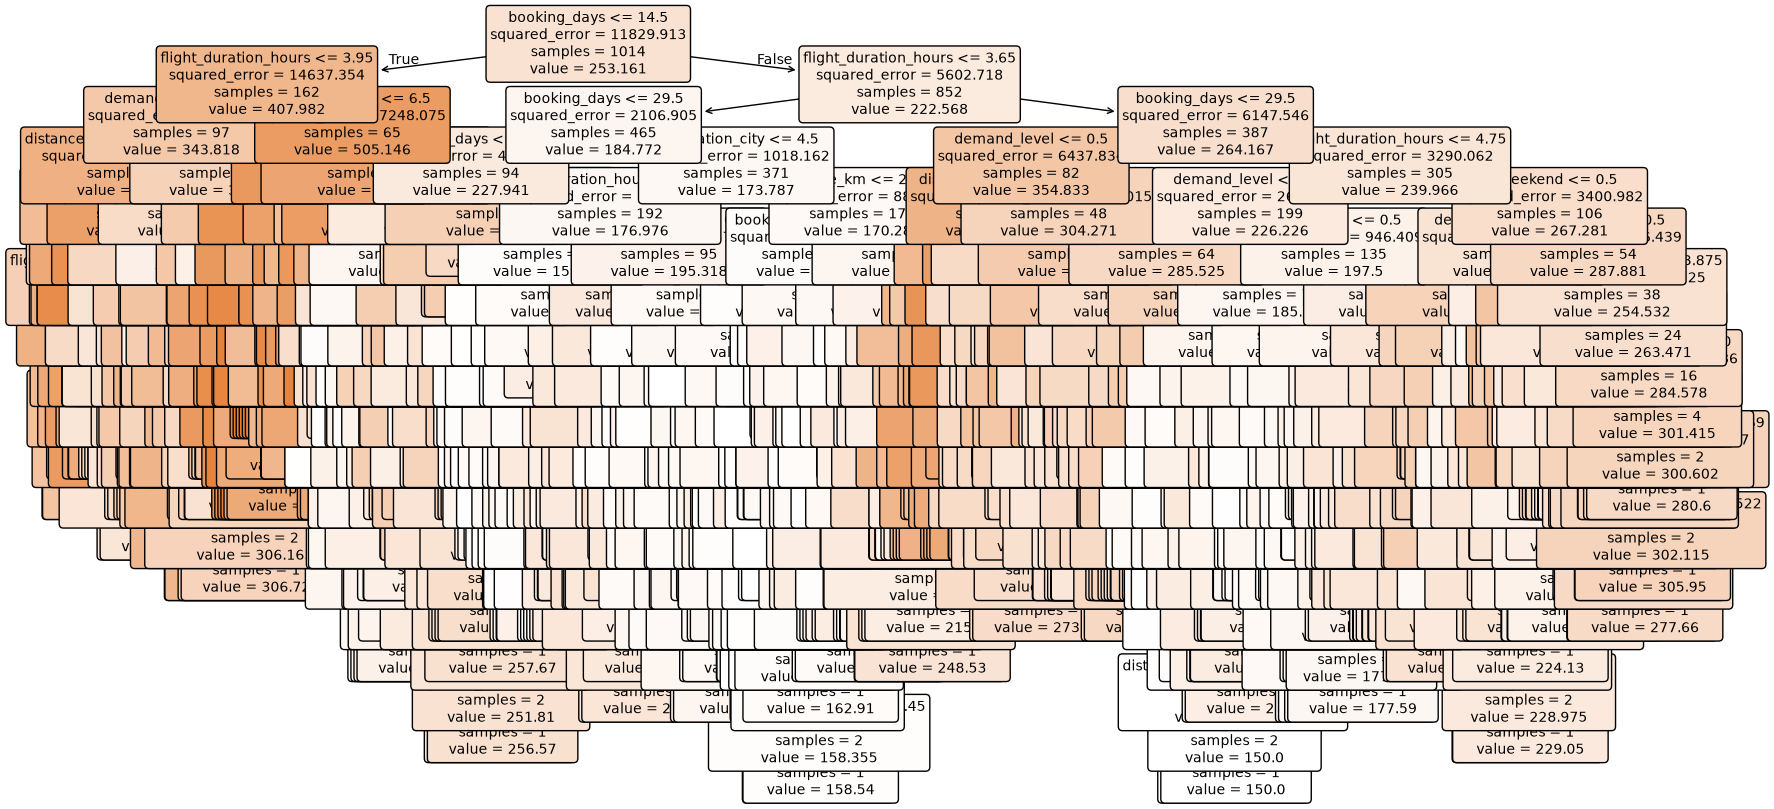

In [46]:
plt.figure(figsize=(20, 10))
tree.plot_tree(estimator,
               feature_names=X_train.columns,
               filled=True,
               rounded=True,
               fontsize=10)
plt.show()